# Google Play Store Apps - EDA

## 1. Load & Clean Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("googleplaystore.csv")

df = df[df["Category"] != "1.9"]                      # drop corrupted row
df = df.drop_duplicates(subset="App", keep="first")    # drop duplicates

df["Installs"] = df["Installs"].str.replace(r"[+,]", "", regex=True)
df["Installs"] = pd.to_numeric(df["Installs"], errors="coerce")

df["Price"] = df["Price"].str.replace("$", "", regex=False)
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

def clean_size(x):
    x = str(x)
    if x.endswith("M"):
        return float(x[:-1])
    if x.endswith("k"):
        return float(x[:-1]) / 1024
    return np.nan

df["Size"] = df["Size"].apply(clean_size)
df["Reviews"] = pd.to_numeric(df["Reviews"], errors="coerce")

df["Category"] = df["Category"].str.upper().str.strip()
df["Genres"] = df["Genres"].str.strip()
df["Type"] = df["Type"].str.strip()
df["Content Rating"] = df["Content Rating"].str.strip()

df["Last Updated"] = pd.to_datetime(df["Last Updated"], errors="coerce")

df = df.dropna(subset=["Type"])
df = df[(df["Rating"] >= 0) & (df["Rating"] <= 5) | df["Rating"].isna()]

print("Clean shape:", df.shape)

Clean shape: (9658, 13)


## 2. Basic Questions

**Average rating**

In [2]:
df["Rating"].mean().round(2)

np.float64(4.17)

**Unique categories**

In [3]:
df["Category"].nunique()

33

**Free vs Paid**

In [4]:
df["Type"].value_counts()

Type
Free    8902
Paid     756
Name: count, dtype: int64

**Most common content rating**

In [5]:
df["Content Rating"].mode()[0]

'Everyone'

**Top 5 installed apps**

In [6]:
df.sort_values("Installs", ascending=False).head(5)[["App", "Installs"]]

,App,Installs
2544,Facebook,1000000000
340,Gmail,1000000000
338,Google Chrome: Fast & Secure,1000000000
336,WhatsApp Messenger,1000000000
335,Messenger – Text and Video Chat for Free,1000000000


**Apps rated >= 4.0**

In [7]:
(df["Rating"] >= 4.0).sum()

np.int64(6286)

**Avg reviews by type**

In [8]:
df.groupby("Type")["Reviews"].mean()

Type
Free    234270.002134
Paid      8724.887566
Name: Reviews, dtype: float64

**Avg size by category**

In [9]:
df.groupby("Category")["Size"].mean().sort_values(ascending=False)

Category
GAME                   41.866570
FAMILY                 27.187747
TRAVEL_AND_LOCAL       24.204375
SPORTS                 24.058153
ENTERTAINMENT          23.043750
PARENTING              22.512963
HEALTH_AND_FITNESS     20.669296
FOOD_AND_DRINK         20.494318
AUTO_AND_VEHICLES      20.036807
MEDICAL                19.188756
EDUCATION              19.056816
FINANCE                17.367863
MAPS_AND_NAVIGATION    16.367773
SOCIAL                 15.983868
HOUSE_AND_HOME         15.970010
VIDEO_PLAYERS          15.792612
PHOTOGRAPHY            15.666053
DATING                 15.661117
SHOPPING               15.490994
LIFESTYLE              14.844516
EVENTS                 13.963617
BUSINESS               13.866891
BEAUTY                 13.795745
COMICS                 13.794456
BOOKS_AND_REFERENCE    13.134057
WEATHER                12.679792
NEWS_AND_MAGAZINES     12.470153
ART_AND_DESIGN         12.370968
PRODUCTIVITY           12.341952
COMMUNICATION          11.306306
P

**Apps updated in 2018**

In [10]:
(df["Last Updated"].dt.year == 2018).sum()

np.int64(6283)

**App size distribution**

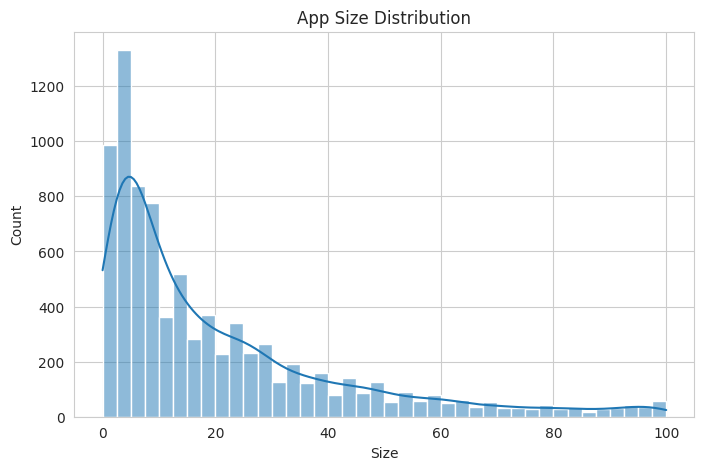

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Size"].dropna(), bins=40, kde=True)
plt.title("App Size Distribution")
plt.show()

## 3. Medium Questions

**Rating by price range (paid apps)**

In [12]:
paid = df[df["Type"] == "Paid"]
price_bins = pd.cut(paid["Price"], bins=[0, 1, 5, 10, 20, 50, 400])
paid.groupby(price_bins, observed=True)["Rating"].mean()

Price
(0, 1]       4.300943
(1, 5]       4.271279
(5, 10]      4.230508
(10, 20]     4.248387
(20, 50]     4.122222
(50, 400]    3.912500
Name: Rating, dtype: float64

**Top rated categories**

In [13]:
df.groupby("Category")["Rating"].mean().sort_values(ascending=False).head(10)

Category
EVENTS                 4.435556
EDUCATION              4.364407
ART_AND_DESIGN         4.357377
BOOKS_AND_REFERENCE    4.344970
PERSONALIZATION        4.332215
PARENTING              4.300000
BEAUTY                 4.278571
GAME                   4.247368
SOCIAL                 4.247291
WEATHER                4.243056
Name: Rating, dtype: float64

**Genres with most 1M+ install apps**

In [14]:
df[df["Installs"] > 1_000_000]["Genres"].value_counts().head(10)

Genres
Tools            172
Action           128
Photography      123
Communication     99
Productivity      91
Entertainment     83
Arcade            81
Sports            79
Shopping          72
Social            67
Name: count, dtype: int64

**Top reviewed apps**

In [15]:
df.sort_values("Reviews", ascending=False).head(10)[["App", "Reviews", "Rating"]]

,App,Reviews,Rating
2544,Facebook,78158306,4.1
336,WhatsApp Messenger,69119316,4.4
2545,Instagram,66577313,4.5
335,Messenger – Text and Video Chat for Free,56642847,4.0
1670,Clash of Clans,44891723,4.6
4005,Clean Master- Space Cleaner & Antivirus,42916526,4.7
1654,Subway Surfers,27722264,4.5
3665,YouTube,25655305,4.3
7536,"Security Master - Antivirus, VPN, AppLock, Boo...",24900999,4.7
1660,Clash Royale,23133508,4.6


**Content rating vs type**

In [16]:
pd.crosstab(df["Content Rating"], df["Type"])

Type,Free,Paid
Content Rating,,
Adults only 18+,3,0
Everyone,7248,655
Everyone 10+,290,31
Mature 17+,375,18
Teen,984,52
Unrated,2,0


**Top categories by total installs**

In [17]:
df.groupby("Category")["Installs"].sum().sort_values(ascending=False).head(5)

Category
GAME             13878924415
COMMUNICATION    11038276251
TOOLS             8001771915
PRODUCTIVITY      5793091369
SOCIAL            5487867902
Name: Installs, dtype: int64

**Rating by content rating**

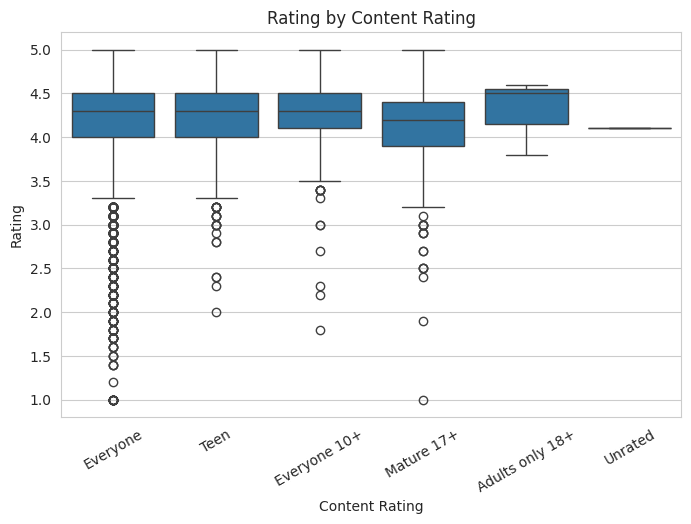

In [18]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Content Rating", y="Rating")
plt.title("Rating by Content Rating")
plt.xticks(rotation=30)
plt.show()

## 4. Advanced Questions

**Top rated apps (min 1000 reviews)**

In [19]:
top_rated = df[df["Reviews"] >= 1000].sort_values("Rating", ascending=False).head(10)
top_rated[["App", "Rating", "Reviews"]]

,App,Rating,Reviews
64,DMV Permit Practice Test 2018 Edition,4.9,6090
61,CDL Practice Test 2018 Edition,4.9,7774
55,Tickets SDA 2018 and Exam from the State Traff...,4.9,10479
1307,StrongLifts 5x5 Workout Gym Log & Personal Tra...,4.9,66791
10552,FK Crvena zvezda,4.9,1211
1260,Six Pack in 30 Days - Abs Workout,4.9,272337
10016,Eddsworld Amino,4.9,3071
177,eBoox new: Reader for fb2 epub zip books,4.9,2739
9625,JW Library,4.9,922752
1258,Lose Belly Fat in 30 Days - Flat Stomach,4.9,38098


**App updates over time**

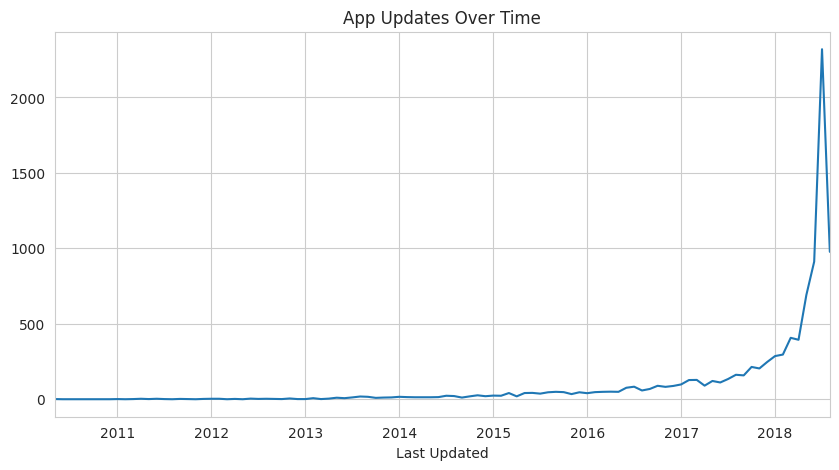

In [20]:
monthly_updates = df.set_index("Last Updated").resample("ME").size()
plt.figure(figsize=(10, 5))
monthly_updates.plot()
plt.title("App Updates Over Time")
plt.show()

**Genre vs rating (min 10 apps per genre)**

In [21]:
genre_stats = df.groupby("Genres")["Rating"].agg(["mean", "count"]).query("count >= 10")
genre_stats.sort_values("mean", ascending=False).head(10)

,mean,count
Genres,,
Casual;Brain Games,4.475000,12
Events,4.435556,45
Puzzle;Brain Games,4.370588,17
Puzzle,4.370000,100
Education;Pretend Play,4.358824,17
Art & Design,4.358182,55
Books & Reference,4.344970,169
Word,4.340909,22
Board;Brain Games,4.340000,15


**Bottom genres by rating**

In [22]:
genre_stats.sort_values("mean").head(10)

,mean,count
Genres,,
Educational,3.871875,32
Dating,3.970149,134
Maps & Navigation,4.036441,118
Tools,4.038912,717
Trivia,4.039286,28
Video Players & Editors,4.044898,147
Travel & Local,4.069355,186
Card,4.072727,44
Entertainment,4.083439,471
